# 🏠 Indian House Price Prediction (XGBoost)

Is notebook me hum step-by-step ek ML model banayenge jo ghar ki details dekh kar **Price (Lakh me)** predict karega.

**Steps:**
1. Libraries import karna
2. Data load karna aur samajhna
3. Graphs (EDA)
4. Data cleaning aur encoding
5. Train / Test split
6. Models train karna: Linear Regression, Random Forest, XGBoost
7. Models compare karna
8. Model save karna (FastAPI ke liye)
9. Ek naye ghar ka price predict karna

> Code jaan-boojh kar simple rakha hai: koi function ya loop nahi, sirf line-by-line code.

## Step 1: Libraries import karna

In [1]:
# Agar libraries install nahi hain to neeche wali line se '#' hata kar run karo
# !pip install pandas numpy matplotlib scikit-learn xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

print("Sab libraries import ho gayi")

Sab libraries import ho gayi


## Step 2: Data load karna

CSV file is notebook ke same folder me honi chahiye.

In [2]:
df = pd.read_csv("indian_house_price_prediction_data.csv")
print("Rows aur columns:", df.shape)
df.head()

Rows aur columns: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [3]:
# Data ki basic jaankari
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

Missing values: 0
Duplicate rows: 0


,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,125000.500000,2.999396,2749.813216,254.586854,0.130597,2006.520012,14.966800,15.503004,18.479988,5.499860,5.498016
std,72168.927986,1.415521,1300.606954,141.349921,0.130747,9.808575,8.948047,8.671618,9.808575,2.878639,2.871860
min,1.000000,1.000000,500.000000,10.000000,0.000000,1990.000000,0.000000,1.000000,2.000000,1.000000,1.000000
25%,62500.750000,2.000000,1623.000000,132.550000,0.050000,1998.000000,7.000000,8.000000,10.000000,3.000000,3.000000
50%,125000.500000,3.000000,2747.000000,253.870000,0.090000,2007.000000,15.000000,15.000000,18.000000,5.000000,5.000000
75%,187500.250000,4.000000,3874.000000,376.880000,0.160000,2015.000000,23.000000,23.000000,27.000000,8.000000,8.000000
max,250000.000000,5.000000,5000.000000,500.000000,0.990000,2023.000000,30.000000,30.000000,35.000000,10.000000,10.000000


## Step 3: Graphs (EDA)

Pehle dekhte hain ki data kaisa dikhta hai.

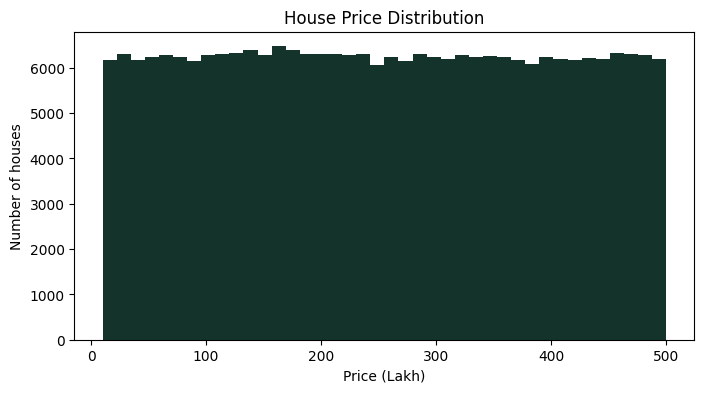

In [5]:
# Graph 1: Price kaise faila hua hai
plt.figure(figsize=(8, 4))
plt.hist(df["Price_in_Lakhs"], bins=40, color="#14342b")
plt.title("House Price Distribution")
plt.xlabel("Price (Lakh)")
plt.ylabel("Number of houses")
plt.show()

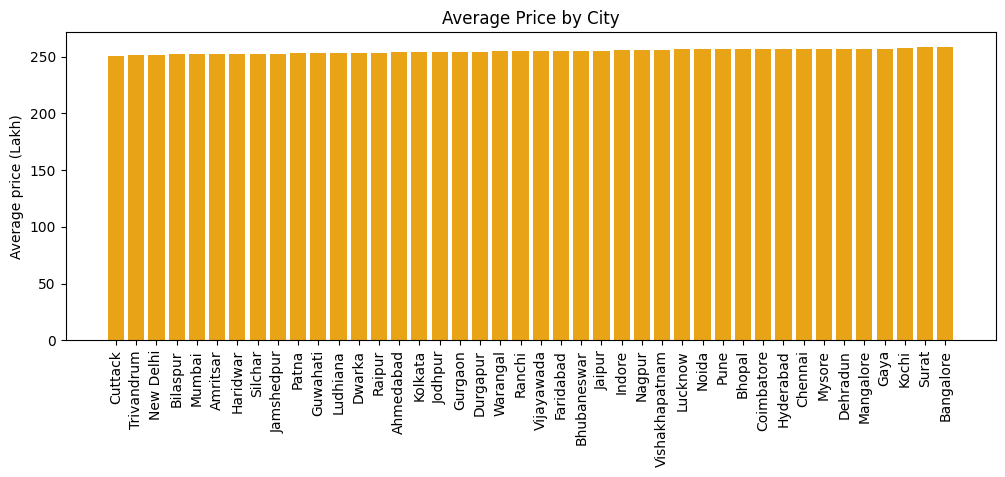

In [6]:
# Graph 2: Har city ka average price
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()

plt.figure(figsize=(12, 4))
plt.bar(city_price.index, city_price.values, color="#e8a317")
plt.xticks(rotation=90)
plt.title("Average Price by City")
plt.ylabel("Average price (Lakh)")
plt.show()

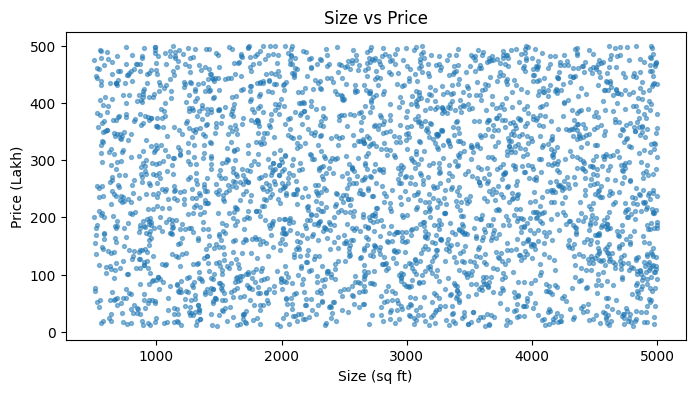

In [7]:
# Graph 3: Size aur Price ka relation (3000 random ghar)
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(8, 4))
plt.scatter(sample["Size_in_SqFt"], sample["Price_in_Lakhs"], s=8, alpha=0.5)
plt.title("Size vs Price")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price (Lakh)")
plt.show()

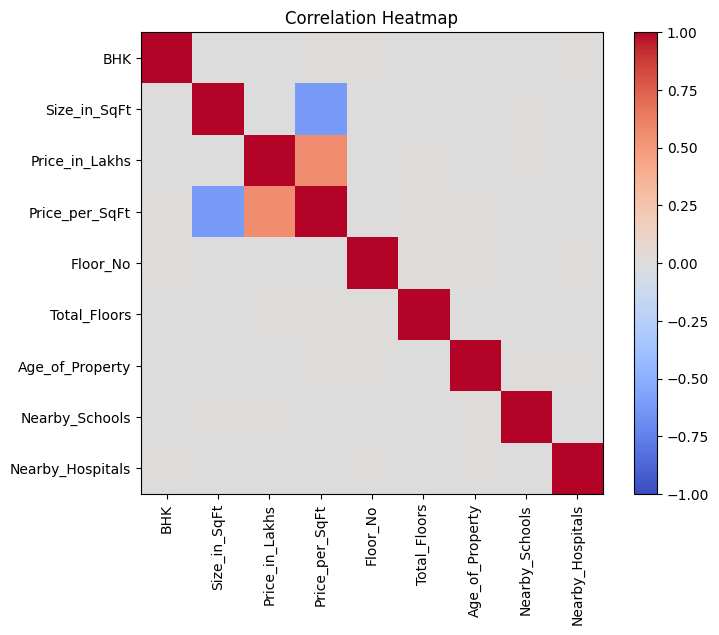

Nearby_Hospitals   -0.002769
Age_of_Property    -0.002714
Size_in_SqFt       -0.002529
Floor_No           -0.001719
BHK                -0.000980
Nearby_Schools      0.000155
Total_Floors        0.001283
Price_per_SqFt      0.555625
Price_in_Lakhs      1.000000
Name: Price_in_Lakhs, dtype: float64


In [8]:
# Graph 4: Correlation (kaun sa column price se kitna judha hai)
numbers = df[["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Floor_No",
              "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals"]]
corr = numbers.corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

print(corr["Price_in_Lakhs"].sort_values())

### ⚠️ Zaroori baat: 2 cheezein dhyan se dekho

**1. Data leakage:** `Price_per_SqFt` asal me `Price / Size` se bana hai. Yaani ye column price ko already jaanta hai. Agar isse model me daala to model "cheating" karega aur real life me (jab price pata hi nahi hota) kaam nahi karega. Isliye isse **hata denge**.

**2. Correlation:** Upar dekho, `Price_per_SqFt` ko chhod kar kisi bhi column ka price se relation lagbhag **0** hai. Iska matlab ye dataset **synthetic (nakli / random)** lagta hai, price ka size, BHK ya city se koi asli connection nahi hai. Isliye final model ka score bahut low aayega. Ye code ki galti nahi, data ki limitation hai.

In [9]:
# Leakage ka saboot: Price / Size ≈ Price_per_SqFt
check = df[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]].head()
check["Price divided by Size"] = check["Price_in_Lakhs"] / check["Size_in_SqFt"]
check

,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Price divided by Size
0,489.76,4740,0.10,0.103325
1,195.52,2364,0.08,0.082707
2,183.79,3642,0.05,0.050464
3,300.29,2741,0.11,0.109555
4,182.90,4823,0.04,0.037922


## Step 4: Data cleaning

- `Amenities` ek text hai ("Gym, Pool, Garden"), isse hum **count** (kitni amenities) me badal denge.
- Ye columns hata denge:
  - `ID` (sirf number hai)
  - `Price_per_SqFt` (leakage)
  - `Year_Built` (`Age_of_Property` se same info milti hai)
  - `State` (City se pata chal jata hai)
  - `Locality` (500 alag values hain, form me dena mushkil)
  - `Amenities` (count bana liya)

In [10]:
df["Amenities_Count"] = df["Amenities"].str.count(",") + 1

df = df.drop(columns=["ID", "State", "Locality", "Amenities", "Year_Built", "Price_per_SqFt"])

print(df.shape)
df.head()

(250000, 18)


,City,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Facing,Owner_Type,Availability_Status,Amenities_Count
0,Chennai,Apartment,1,4740,489.76,Furnished,22,1,35,10,3,High,No,No,West,Owner,Ready_to_Move,5
1,Pune,Independent House,3,2364,195.52,Unfurnished,21,20,17,8,1,Low,No,Yes,North,Builder,Under_Construction,5
2,Ludhiana,Apartment,2,3642,183.79,Semi-furnished,19,27,28,9,8,Low,Yes,No,South,Broker,Ready_to_Move,4
3,Jodhpur,Independent House,2,2741,300.29,Furnished,21,26,34,5,7,High,Yes,Yes,North,Builder,Ready_to_Move,5
4,Jaipur,Villa,4,4823,182.90,Semi-furnished,3,2,23,4,9,Low,No,Yes,East,Builder,Ready_to_Move,5


## Step 5: Text ko numbers me badalna (Encoding)

ML model sirf numbers samajhta hai. `get_dummies` har text value ke liye alag 0/1 column bana deta hai.

In [11]:
df_encoded = pd.get_dummies(df, dtype=int)

# X = input (ghar ki details), y = output (price)
X = df_encoded.drop(columns=["Price_in_Lakhs"])
y = df_encoded["Price_in_Lakhs"]

print("Input columns:", X.shape[1])
X.head()

Input columns: 72


,BHK,Size_in_SqFt,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Amenities_Count,City_Ahmedabad,City_Amritsar,...,Security_Yes,Facing_East,Facing_North,Facing_South,Facing_West,Owner_Type_Broker,Owner_Type_Builder,Owner_Type_Owner,Availability_Status_Ready_to_Move,Availability_Status_Under_Construction
0,1,4740,22,1,35,10,3,5,0,0,...,0,0,0,0,1,0,0,1,1,0
1,3,2364,21,20,17,8,1,5,0,0,...,1,0,1,0,0,0,1,0,0,1
2,2,3642,19,27,28,9,8,4,0,0,...,0,0,0,1,0,1,0,0,1,0
3,2,2741,21,26,34,5,7,5,0,0,...,1,0,1,0,0,0,1,0,1,0
4,4,4823,3,2,23,4,9,5,0,0,...,1,1,0,0,0,0,1,0,1,0


## Step 6: Train / Test split

80% data se model seekhega, 20% data se hum uski jaanch karenge.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 200000
Testing rows: 50000


## Step 7: Models train karna

### Baseline (sabse simple)
Agar hum har ghar ka price sirf **average** bata dein to score kya aayega? Koi bhi model isse behtar hona chahiye.

In [13]:
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_r2 = r2_score(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline R2:", round(baseline_r2, 4))
print("Baseline MAE:", round(baseline_mae, 2), "Lakh")

Baseline R2: -0.0
Baseline MAE: 122.32 Lakh


### Model 1: Linear Regression

In [14]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_r2 = r2_score(y_test, lr_pred)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print("Linear Regression R2:", round(lr_r2, 4))
print("Linear Regression MAE:", round(lr_mae, 2), "Lakh")

Linear Regression R2: -0.0002
Linear Regression MAE: 122.32 Lakh


### Model 2: Random Forest
(Isme 1-2 minute lag sakte hain.)

In [28]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=500,
                                 random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest R2:", round(rf_r2, 4))
print("Random Forest MAE:", round(rf_mae, 2), "Lakh")

Random Forest R2: -0.0001
Random Forest MAE: 122.33 Lakh


### Model 3: XGBoost (hamara main model)

In [26]:
xgb_model = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8,
                         random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_r2 = r2_score(y_test, xgb_pred)
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))

# Train score bhi dekho (overfitting check)
xgb_train_r2 = r2_score(y_train, xgb_model.predict(X_train))

print("XGBoost Train R2:", round(xgb_train_r2, 4))
print("XGBoost Test R2:", round(xgb_r2, 4))
print("XGBoost MAE:", round(xgb_mae, 2), "Lakh")

XGBoost Train R2: 0.0071
XGBoost Test R2: -0.0008
XGBoost MAE: 122.35 Lakh


## Step 8: Models compare karna

In [17]:
results = pd.DataFrame({
    "Model": ["Baseline (average)", "Linear Regression", "Random Forest", "XGBoost"],
    "R2 score": [baseline_r2, lr_r2, rf_r2, xgb_r2],
    "MAE (Lakh)": [baseline_mae, lr_mae, rf_mae, xgb_mae],
    "RMSE (Lakh)": [baseline_rmse, lr_rmse, rf_rmse, xgb_rmse]
})
results

,Model,R2 score,MAE (Lakh),RMSE (Lakh)
0,Baseline (average),-0.000001,122.317776,141.193240
1,Linear Regression,-0.000180,122.321462,141.205836
2,Random Forest,-0.000526,122.342481,141.230301
3,XGBoost,-0.000809,122.350796,141.250270


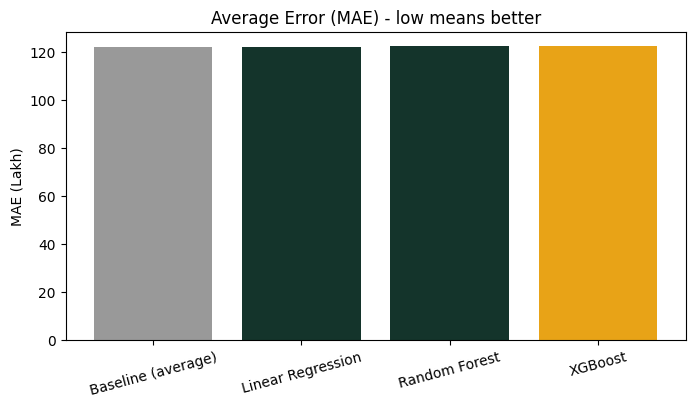

In [19]:
plt.figure(figsize=(8, 4))
plt.bar(results["Model"], results["MAE (Lakh)"], color=["#999999", "#14342b", "#14342b", "#e8a317"])
plt.title("Average Error (MAE) - low means better")
plt.ylabel("MAE (Lakh)")
plt.xticks(rotation=15)
plt.show()

**Result kaise padhein:**
- **R2 = 1** matlab perfect, **R2 = 0** matlab model average se behtar nahi, **R2 negative** matlab average se bhi kharab.
- **MAE** = model ka average galti (Lakh me).

Is dataset me sab models ka R2 lagbhag **0** aana normal hai, kyunki price random hai (Step 3 ki baat). Agar tumhe R2 0.8+ chahiye to real data chahiye (jaise 99acres / MagicBricks ka scraped data, ya Kaggle ka real Indian housing dataset).

### Actual vs Predicted (XGBoost)
Agar model accha hota to points ek seedhi line ke paas hote.

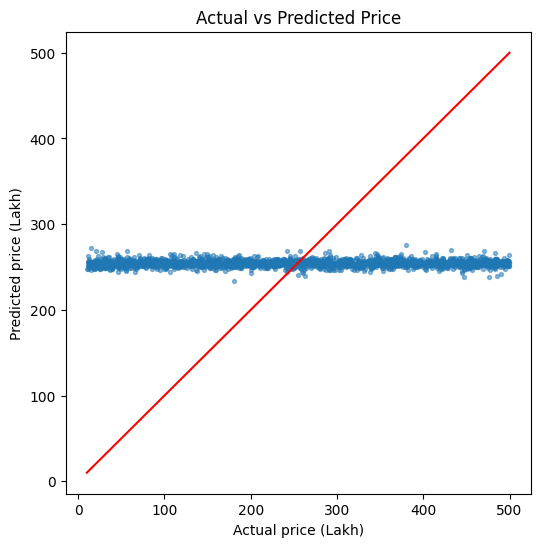

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test[:2000], xgb_pred[:2000], s=8, alpha=0.5)
plt.plot([10, 500], [10, 500], color="red")
plt.title("Actual vs Predicted Price")
plt.xlabel("Actual price (Lakh)")
plt.ylabel("Predicted price (Lakh)")
plt.show()

### Kaun se features model ke liye important hain?

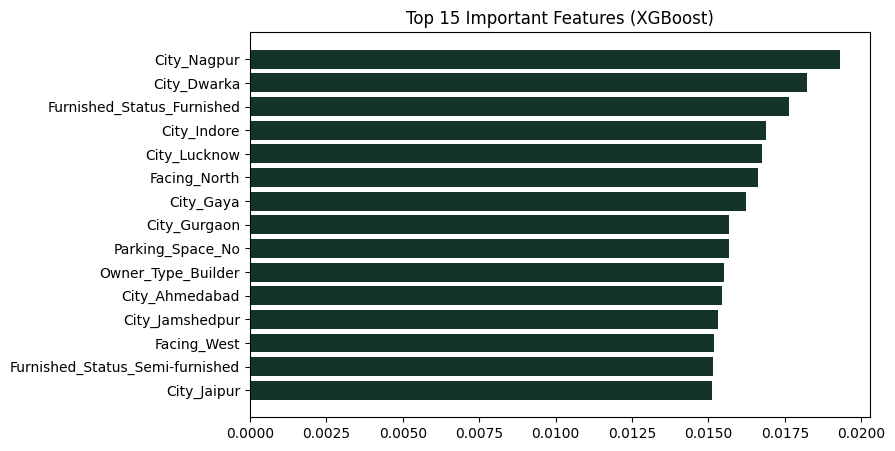

In [21]:
importance = pd.Series(xgb_model.feature_importances_, index=X.columns)
top15 = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
plt.barh(top15.index[::-1], top15.values[::-1], color="#14342b")
plt.title("Top 15 Important Features (XGBoost)")
plt.show()

## Step 9: Model save karna

FastAPI ko 2 files chahiye:
- `xgb_model.json` (trained model)
- `model_columns.json` (columns ki list aur unka order)

**Dono files ko `house-price-app` folder me copy karna mat bhoolna.**

In [22]:
xgb_model.save_model("xgb_model.json")

columns_file = open("model_columns.json", "w")
json.dump(list(X.columns), columns_file)
columns_file.close()

print("Saved: xgb_model.json aur model_columns.json")

Saved: xgb_model.json aur model_columns.json


## Step 10: Naye ghar ka price predict karna

Yahi steps FastAPI (`main.py`) me bhi chalte hain.

In [ ]:
# Ghar ki details yahan badal kar dekho
new_house = pd.DataFrame([{
    "City": "Ahmedabad",
    "Property_Type": "Apartment",
    "BHK": 3,
    "Size_in_SqFt": 1300,
    "Furnished_Status": "Semi-furnished",
    "Floor_No": 5,
    "Total_Floors": 12,
    "Age_of_Property": 5,
    "Nearby_Schools": 5,
    "Nearby_Hospitals": 4,
    "Public_Transport_Accessibility": "High",
    "Parking_Space": "Yes",
    "Security": "Yes",
    "Amenities_Count": 3,
    "Facing": "East",
    "Owner_Type": "Owner",
    "Availability_Status": "Ready_to_Move"
}])

# 1. Same encoding
new_house = pd.get_dummies(new_house, dtype=int)

# 2. Training jaise same columns aur order (jo missing hain wo 0)
new_house = new_house.reindex(columns=X.columns, fill_value=0)

# 3. Predict
predicted_price = xgb_model.predict(new_house)[0]

print("Predicted price:", round(float(predicted_price), 2), "Lakh")
print("approximately:", round(float(predicted_price) / 100, 2), "Crore")

Predicted price: 260.14 Lakh
Yaani lagbhag: 2.6 Crore


## ✅ Done!

Ab `xgb_model.json` aur `model_columns.json` ko `house-price-app` folder me daalo aur README.md ke hisaab se Render par deploy karo.